# Exploring Seoul bike demand

Hourly rentals from Seoul's public bike-sharing system, 1 December 2017 to 30 November 2018, with weather and calendar data (the *Seoul Bike Sharing Demand* dataset from the UCI Machine Learning Repository). This notebook checks the data and looks at the patterns a forecast has to capture. The hypothesis tests are in `02_hypothesis_tests.ipynb` and the model in `03_forecasting.ipynb`.

In [1]:
try:
    import bikeshare  # noqa: F401
except ModuleNotFoundError:  # running without `pip install -e .`
    import sys
    sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bikeshare import data, features, plotting

plotting.use_style()
raw = pd.read_csv(data.DATA_PATH)
hourly = data.load()
print(f"{len(raw):,} rows x {raw.shape[1]} columns | missing values: {raw.isna().sum().sum()} | "
      f"duplicate rows: {raw.duplicated().sum()}")
print(f"{hourly['date'].nunique()} days, {hourly['timestamp'].min():%d %b %Y %H:%M} to "
      f"{hourly['timestamp'].max():%d %b %Y %H:%M}, exactly one row per hour")
raw.head()

8,760 rows x 14 columns | missing values: 0 | duplicate rows: 0
365 days, 01 Dec 2017 00:00 to 30 Nov 2018 23:00, exactly one row per hour


,Date,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/17,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/17,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/17,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/17,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/17,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## 1. Data checks

**Dates are day-first with a two-digit year.** `01/12/17` is 1 December 2017. Read without a format, pandas takes it as 12 January 2017, which was the v1 bug: it only shows up for days 1 to 12 of each month, because a day above 12 cannot be a month. `data.load()` always passes the format, and `tests/test_data.py` checks it.

In [2]:
examples = raw["Date"].iloc[[0, 5 * 24, 12 * 24]]
pd.DataFrame({
    "in the file": examples.to_numpy(),
    "read without a format (v1)": examples.apply(pd.to_datetime).dt.date.to_numpy(),
    "read day-first (v2)": pd.to_datetime(examples, format="%d/%m/%y").dt.date.to_numpy(),
})

,in the file,read without a format (v1),read day-first (v2)
0,01/12/17,2017-01-12,2017-12-01
1,06/12/17,2017-06-12,2017-12-06
2,13/12/17,2017-12-13,2017-12-13


In [3]:
closed = hourly[~hourly["functioning"]]
print(f"{len(closed)} closed hours on {closed['date'].nunique()} days. No rentals were possible, "
      "so these hours are left out of every analysis.")
closed.groupby(closed["date"].dt.date).size().rename("closed hours").to_frame().T

295 closed hours on 13 days. No rentals were possible, so these hours are left out of every analysis.


date,2018-04-11,2018-05-10,2018-09-18,2018-09-19,2018-09-28,2018-09-30,2018-10-02,2018-10-04,2018-10-06,2018-10-09,2018-11-03,2018-11-06,2018-11-09
closed hours,24,24,24,24,24,24,24,24,7,24,24,24,24


## 2. Demand over the year

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


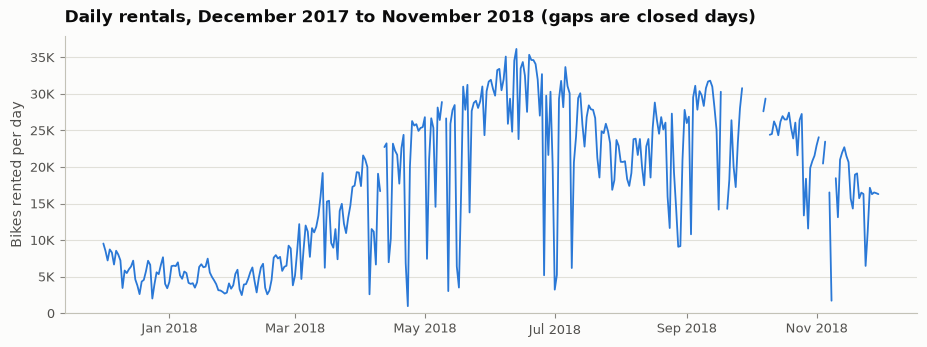

busiest day: Wed 13 Jun 2018 with 36,149 rentals; quietest full day: Mon 23 Apr 2018 with 977


In [4]:
daily = hourly.groupby("date").agg(rentals=("rentals", "sum"), open_hours=("functioning", "sum"))
daily.loc[daily["open_hours"] < 24, "rentals"] = np.nan  # closed or part-closed days
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily.index, daily["rentals"], color=plotting.BLUE, linewidth=1.3)
ax.yaxis.set_major_formatter(plotting.thousands)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(bottom=0)
ax.set_ylabel("Bikes rented per day")
ax.set_title("Daily rentals, December 2017 to November 2018 (gaps are closed days)")
plotting.save(fig, "daily_rentals")
plt.show()
busiest = daily["rentals"].idxmax()
print(f"busiest day: {busiest:%a %d %b %Y} with {daily['rentals'].max():,.0f} rentals; "
      f"quietest full day: {daily['rentals'].idxmin():%a %d %b %Y} with {daily['rentals'].min():,.0f}")

## 3. The daily rhythm

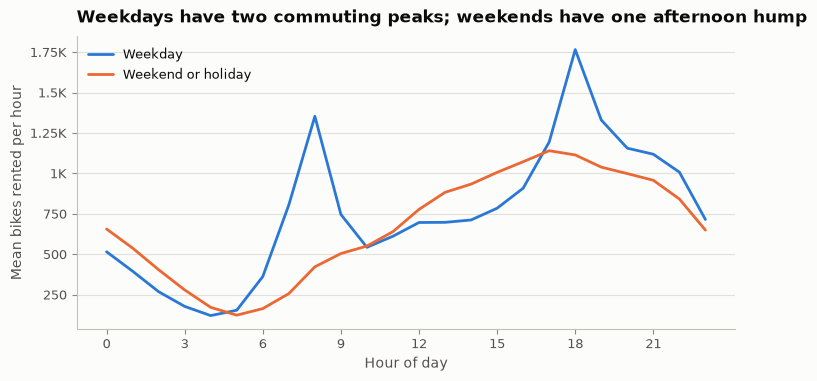

day_type,Weekday,Weekend or holiday
hour,,
8,1354.0,422.0
14,712.0,934.0
18,1766.0,1115.0


In [5]:
open_hours = hourly[hourly["functioning"]].copy()
open_hours["day_type"] = np.where((open_hours["date"].dt.weekday >= 5) | open_hours["holiday"],
                                  "Weekend or holiday", "Weekday")
profile = open_hours.groupby(["day_type", "hour"])["rentals"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for column, color in [("Weekday", plotting.BLUE), ("Weekend or holiday", plotting.ORANGE)]:
    ax.plot(profile.index, profile[column], color=color, label=column)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean bikes rented per hour")
ax.yaxis.set_major_formatter(plotting.thousands)
ax.set_title("Weekdays have two commuting peaks; weekends have one afternoon hump")
ax.legend(loc="upper left")
plotting.save(fig, "hourly_profile")
plt.show()
profile.loc[[8, 14, 18]].round(0)

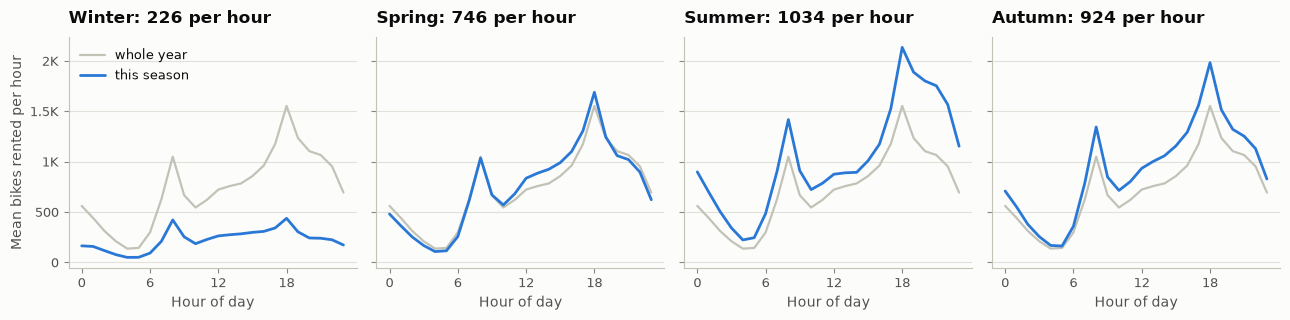

In [6]:
season_profile = open_hours.groupby(["season", "hour"], observed=True)["rentals"].mean().unstack(0)
whole_year = open_hours.groupby("hour")["rentals"].mean()
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, season in zip(axes, data.SEASONS):
    ax.plot(whole_year.index, whole_year.values, color=plotting.CONTEXT, linewidth=1.6, label="whole year")
    ax.plot(season_profile.index, season_profile[season], color=plotting.BLUE, label="this season")
    mean = open_hours.loc[open_hours["season"] == season, "rentals"].mean()
    ax.set_title(f"{season}: {mean:.0f} per hour")
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Mean bikes rented per hour")
axes[0].yaxis.set_major_formatter(plotting.thousands)
axes[0].legend(loc="upper left")
fig.tight_layout()
plotting.save(fig, "season_profiles")
plt.show()

## 4. Weather

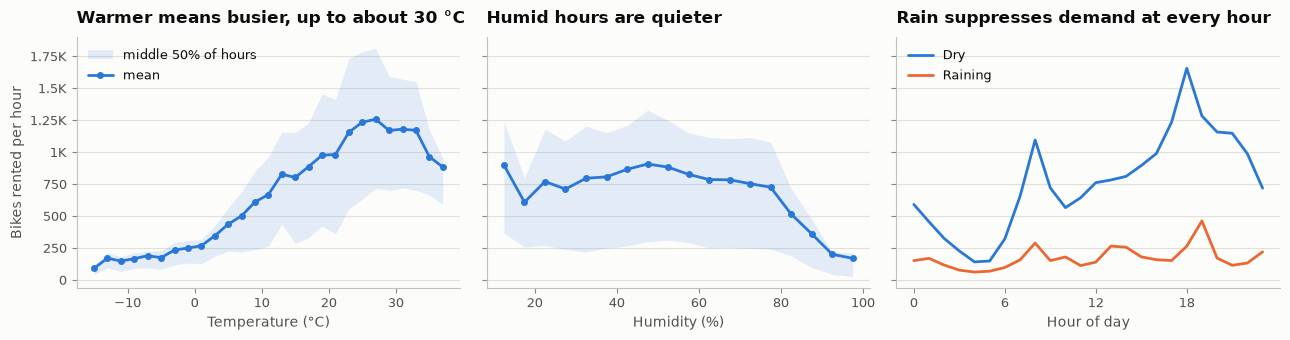

6.1% of open hours had rain; 5.2% had snowfall recorded


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, column, bins, label in [(axes[0], "temperature", np.arange(-18, 41, 2), "Temperature (°C)"),
                                (axes[1], "humidity", np.arange(0, 101, 5), "Humidity (%)")]:
    grouped = open_hours.groupby(pd.cut(open_hours[column], bins), observed=True)["rentals"]
    binned = pd.DataFrame({"mean": grouped.mean(), "q25": grouped.quantile(0.25), "q75": grouped.quantile(0.75),
                           "hours": grouped.size()})
    binned = binned[binned["hours"] >= 20]
    mids = [interval.mid for interval in binned.index]
    ax.fill_between(mids, binned["q25"], binned["q75"], color=plotting.BLUE, alpha=0.12, linewidth=0,
                    label="middle 50% of hours")
    ax.plot(mids, binned["mean"], color=plotting.BLUE, marker="o", markersize=4, label="mean")
    ax.set_xlabel(label)
axes[0].set_ylabel("Bikes rented per hour")
axes[0].yaxis.set_major_formatter(plotting.thousands)
axes[0].legend(loc="upper left")
axes[0].set_title("Warmer means busier, up to about 30 °C")
axes[1].set_title("Humid hours are quieter")

wet = open_hours.assign(rain=np.where(open_hours["rainfall"] > 0, "Raining", "Dry"))
by_rain = wet.groupby(["rain", "hour"])["rentals"].mean().unstack(0)
for column, color in [("Dry", plotting.BLUE), ("Raining", plotting.ORANGE)]:
    axes[2].plot(by_rain.index, by_rain[column], color=color, label=column)
axes[2].set_xticks(range(0, 24, 6))
axes[2].set_xlabel("Hour of day")
axes[2].legend(loc="upper left")
axes[2].set_title("Rain suppresses demand at every hour")
fig.tight_layout()
plotting.save(fig, "weather_relationships")
plt.show()
print(f"{(open_hours['rainfall'] > 0).mean():.1%} of open hours had rain; "
      f"{(open_hours['snowfall'] > 0).mean():.1%} had snowfall recorded")

## 5. Correlations

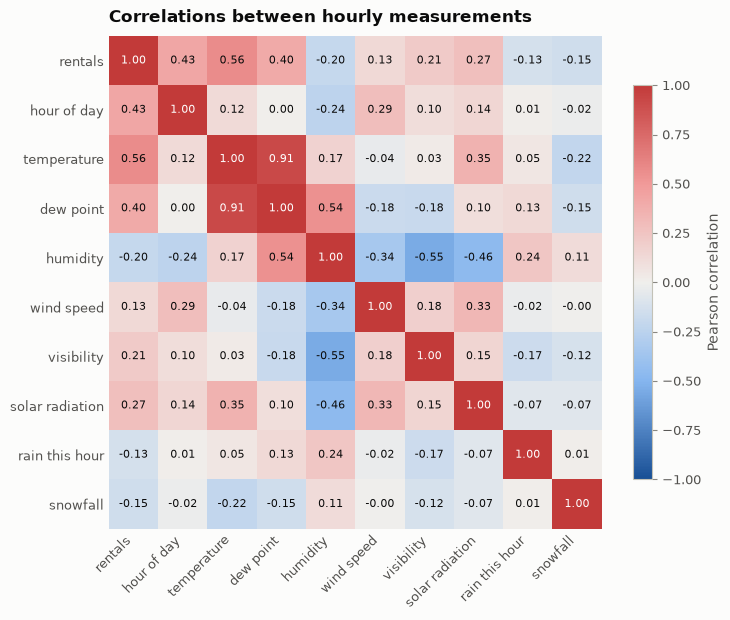

dew point vs temperature: r = 0.91. Dew point is dropped: it is almost a copy of temperature, and with humidity it adds little new information.


In [8]:
numeric = ["rentals", "hour", "temperature", "dew_point", "humidity", "wind_speed", "visibility",
           "solar_radiation", "rainfall", "snowfall"]
corr = open_hours[numeric].corr()
labels = [features.LABELS.get(c, c.replace("_", " ")) for c in numeric]
fig, ax = plt.subplots(figsize=(8, 6.4))
image = ax.imshow(corr, cmap=plotting.DIVERGING, vmin=-1, vmax=1)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if abs(value) > 0.6 else plotting.INK)
ax.set_xticks(range(len(numeric)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(numeric)), labels)
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlations between hourly measurements")
plotting.save(fig, "correlations")
plt.show()
print(f"dew point vs temperature: r = {corr.loc['dew_point', 'temperature']:.2f}. Dew point is dropped: "
      "it is almost a copy of temperature, and with humidity it adds little new information.")

## 6. The target

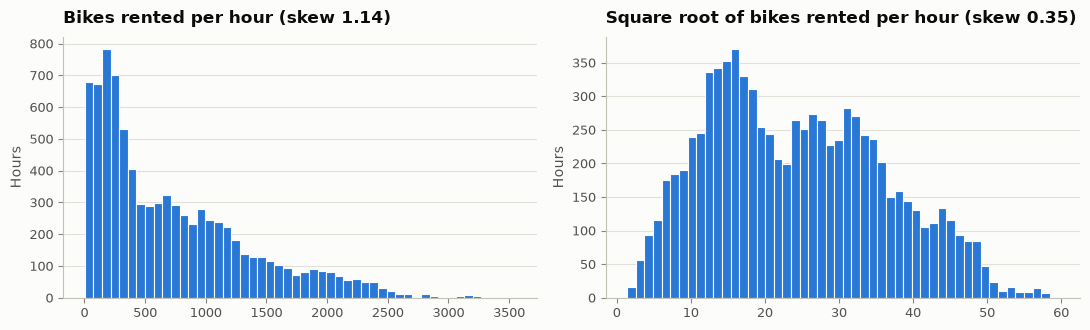

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, values, title in [(axes[0], open_hours["rentals"], "Bikes rented per hour"),
                          (axes[1], np.sqrt(open_hours["rentals"]), "Square root of bikes rented per hour")]:
    ax.hist(values, bins=50, color=plotting.BLUE, edgecolor=plotting.SURFACE, linewidth=0.8)
    ax.set_title(f"{title} (skew {values.skew():.2f})")
    ax.set_ylabel("Hours")
fig.tight_layout()
plt.show()

## Takeaways for the model

- **Two kinds of day.** Weekdays have sharp commuting peaks (about 1,350 bikes per hour at 8:00 and 1,770 at 18:00). Weekends and holidays have a broad afternoon-to-evening hump. The model needs hour of day *and* day type.
- **The level moves.** Average demand runs from 226 bikes per hour in winter to 1,034 in summer, and it swings from day to day. Recent demand (yesterday, last week) is the natural way to set the level for tomorrow.
- **Weather is essential.** Demand rises with temperature up to the high 20s °C and drops when humidity passes about 80%. Rain falls in only 6% of hours, but it suppresses demand at every hour of the day.
- **Clean-up.** Drop the 13 closed days (295 hours). Read dates day-first. Drop dew point, which is nearly a copy of temperature (r = 0.91). The target is right-skewed (skew 1.14), and a square root brings that down to 0.35.